In [1]:
import sys
sys.path.append("..")

from utils import *

# Schatten en betrouwbaarheid

## Puntschattingen

In [4]:
def sample_mean(data):
    """Puntschatting van het populatiegemiddelde (mu) via steekproefgemiddelde."""
    return np.mean(data)

def sample_variance(data, ddof=1):
    """
    Puntschatting van de populatievariantie (σ²).
    ddof=1 voor steekproefvariantie (standaard).
    """
    return np.var(data, ddof=ddof)

def sample_std(data, ddof=1):
    return np.sqrt( sample_variance(data, ddof) )

def proportion_estimate(successes, num_trials):
    """
    Puntschatting van een populatieproportie (p̂).
    - Bij binaire data: successes = aantal successen, n = steekproefgrootte.
    - Bij array input: successes = lijst/array met 0/1 waarden.
    """
    if isinstance(successes, (list, np.ndarray, pd.Series)) and num_trials is None:
        successes = np.sum(successes)
        num_trials = len(successes)
    elif num_trials is None:
        raise ValueError("n is verplicht als je alleen het aantal successen geeft.")
    
    return successes / num_trials

## Betrouwbaarheidsintervallen

In [6]:
def confidence_interval_normal(sample_mean=0, sample_std=1, sigma=None, sample_size=100, alpha=0.05):

    confidence_level = 1 - alpha
    confidence_percentage = int(100 * confidence_level)
    
    if sigma:
        z = norm.ppf(1-alpha/2)
        left = sample_mean - z * sigma / sqrt(sample_size)
        right = sample_mean + z * sigma / sqrt(sample_size)

        latex_code = f"""
            Omdat $\\sigma = {sigma}$ bekend is, kunnen we de normale verdeling gebruiken.
            De $z$-waarde die hoort bij $\\SI{{{confidence_percentage}}}{{\\percent}}$ betrouwbaarheid, oftewel $\\alpha = {alpha}$, is (in het geval van tweezijdige intervallen) gelijk aan
            \\[
                z_{{\\alpha/2}} = \\invnorm(\\opp=1-\\frac{{\\alpha}}{{2}}) = \\invnorm(\\opp={1-alpha/2}) \\approx {pretty_print(z)}.
            \\]
            Het \\SI{{{confidence_percentage}}}{{\\percent}}-betrouwbaarheidsinterval wordt dan gegeven door
            \\begin{{align*}}
                [\\overline{{x}} - z_{{\\alpha/2}} \\cdot \\frac{{ \\sigma }}{{ \\sqrt{{ n }} }}, \\overline{{x}} + z_{{\\alpha/2}} \\cdot \\frac{{ \\sigma }}{{ \\sqrt{{ n }} }}] \\\\
                &= [{pretty_print(sample_mean)} - {pretty_print(z)} \\cdot \\frac{{ {pretty_print(sigma)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}, {pretty_print(sample_mean)} + {pretty_print(z)} \\cdot \\frac{{ {pretty_print(sigma)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}] \\\\
                &= [{pretty_print(left)}, {pretty_print(right)}].
            \\end{{align*}}
        """
    else:
        if sample_size >= 30:
            z = norm.ppf(1-alpha/2)
            left = sample_mean - z * sample_std / sqrt(sample_size)
            right = sample_mean + z * sample_std / sqrt(sample_size)
    
            latex_code = f"""
                Hoewel $\\sigma$ onbekend is, kunnen we toch met de normale benadering werken omdat de steekproefgrootte $n = {sample_size} \\ge 30$ is.
                Hierbij mogen we de onbekende $\\sigma$ schatten met de steekproefstandaardafwijking $s$.
                De $z$-waarde die hoort bij \\SI{{{confidence_percentage}}}{{\\percent}} betrouwbaarheid, oftewel $\\alpha = {alpha}$, is (in het geval van tweezijdige intervallen) gelijk aan
                \\[
                    z_{{\\alpha/2}} = \\invnorm(\\opp=1-\\frac{{\\alpha}}{{2}}) = \\invnorm(\\opp={1-alpha/2}) \\approx {pretty_print(z)}.
                \\]
                Het \\SI{{{confidence_percentage}}}{{\\percent}}-betrouwbaarheidsinterval wordt dan gegeven door
                \\begin{{align*}}
                    [\\overline{{x}} - z_{{\\alpha/2}} \\cdot \\frac{{ s }}{{ \\sqrt{{ n }} }}, \\overline{{x}} + z_{{\\alpha/2}} \\cdot \\frac{{ s }}{{ \\sqrt{{ n }} }}] \\\\
                    &= [{pretty_print(sample_mean)} - {pretty_print(z)} \\cdot \\frac{{ {pretty_print(sample_std)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}, {pretty_print(sample_mean)} + {pretty_print(z)} \\cdot \\frac{{ {pretty_print(sample_std)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}] \\\\
                    &= [{pretty_print(left)}, {pretty_print(right)}].
                \\end{{align*}}
            """
        else:
            tval = t.ppf(1-alpha/2, df=sample_size-1)
            left = sample_mean - tval * sample_std / sqrt(sample_size)
            right = sample_mean + tval * sample_std / sqrt(sample_size)
    
            latex_code = f"""
                Omdat $\\sigma$ onbekend is en de steekproefgrootte $n = {sample_size} < 30$ is, moeten we gebruik maken van de $t$-verdeling.
                De $t$-waarde die hoort bij \\SI{{{confidence_percentage}}}{{\\percent}} betrouwbaarheid, oftewel $\\alpha = {alpha}$, is (in het geval van tweezijdige intervallen) gelijk aan
                \\[
                    t = \\invt(\\opp=1-\\frac{{\\alpha}}{{2}}, \\df=n-1) = \\invt(\\opp={1-alpha/2}, \\df={sample_size-1}) \\approx {pretty_print(tval)}.
                \\]
                Het \\SI{{{confidence_percentage}}}{{\\percent}}-betrouwbaarheidsinterval wordt dan gegeven door
                \\begin{{align*}}
                    [\\samplemeanx - t \\cdot \\frac{{ \\samplestd }}{{ \\sqrt{{ n }} }}, \\samplemeanx + t \\cdot \\frac{{ \\samplestd }}{{ \\sqrt{{ n }} }}] \\\\
                    &= [{pretty_print(sample_mean)} - {pretty_print(tval)} \\cdot \\frac{{ {pretty_print(sample_std)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}, {pretty_print(sample_mean)} + {pretty_print(tval)} \\cdot \\frac{{ {pretty_print(sample_std)} }}{{ \\sqrt{{ {pretty_print(sample_size)} }} }}] \\\\
                    &= [{pretty_print(left)}, {pretty_print(right)}].
                \\end{{align*}}
            """
    print(latex_code)

confidence_interval_normal(sample_mean=14.1, sample_std=1.4, sample_size=18, alpha=0.05)


                Omdat $\sigma$ onbekend is en de steekproefgrootte $n = 18 < 30$ is, moeten we gebruik maken van de $t$-verdeling.
                De $t$-waarde die hoort bij \SI{95}{\percent} betrouwbaarheid, oftewel $\alpha = 0.05$, is (in het geval van tweezijdige intervallen) gelijk aan
                \[
                    t = \invt(\opp=1-\frac{\alpha}{2}, \df=n-1) = \invt(\opp=0.975, \df=17) \approx 2.1098.
                \]
                Het \SI{95}{\percent}-betrouwbaarheidsinterval wordt dan gegeven door
                \begin{align*}
                    [\samplemeanx - t \cdot \frac{ \samplestd }{ \sqrt{ n } }, \samplemeanx + t \cdot \frac{ \samplestd }{ \sqrt{ n } }] \\
                    &= [14.1000 - 2.1098 \cdot \frac{ 1.4000 }{ \sqrt{ 18.0000 } }, 14.1000 + 2.1098 \cdot \frac{ 1.4000 }{ \sqrt{ 18.0000 } }] \\
                    &= [13.4038, 14.7962].
                \end{align*}
            


In [7]:
data = np.array([2.94, 3.00, 2.90, 2.75, 3.00, 2.95,
2.90 ,2.75 ,2.95 ,2.82 ,2.81, 3.05])
mean = np.mean(data)
std = np.std(data, ddof=1)

confidence_interval_normal(sample_mean=mean, sample_std=std, sigma=None, sample_size=12, alpha=0.01)
confidence_interval_normal(sample_mean=mean, sample_std=std, sigma=None, sample_size=12, alpha=0.02)


                Omdat $\sigma$ onbekend is en de steekproefgrootte $n = 12 < 30$ is, moeten we gebruik maken van de $t$-verdeling.
                De $t$-waarde die hoort bij \SI{99}{\percent} betrouwbaarheid, oftewel $\alpha = 0.01$, is (in het geval van tweezijdige intervallen) gelijk aan
                \[
                    t = \invt(\opp=1-\frac{\alpha}{2}, \df=n-1) = \invt(\opp=0.995, \df=11) \approx 3.1058.
                \]
                Het \SI{99}{\percent}-betrouwbaarheidsinterval wordt dan gegeven door
                \begin{align*}
                    [\samplemeanx - t \cdot \frac{ \samplestd }{ \sqrt{ n } }, \samplemeanx + t \cdot \frac{ \samplestd }{ \sqrt{ n } }] \\
                    &= [2.9017 - 3.1058 \cdot \frac{ 0.0993 }{ \sqrt{ 12.0000 } }, 2.9017 + 3.1058 \cdot \frac{ 0.0993 }{ \sqrt{ 12.0000 } }] \\
                    &= [2.8126, 2.9907].
                \end{align*}
            

                Omdat $\sigma$ onbekend is en de steekproefgrootte $n = 12 

### Minimale steekproefgrootte

In [9]:
def minimale_steekproefgrootte(sample_std=1, sigma=None, afwijking=1, alpha=0.05):
    confidence_level = 1 - alpha
    confidence_percentage = int(100 * confidence_level)

    if sigma:
        z = norm.ppf(1-alpha/2)
        n = (z * sigma / afwijking) ** 2
        latex_code = f"""
            Omdat $\\sigma = {sigma}$ bekend is, kunnen we de normale verdeling gebruiken.
            De $z$-waarde die hoort bij \\SI{{{confidence_percentage}}}{{\\percent}} betrouwbaarheid, oftewel $\\alpha = {alpha}$, is (in het geval van tweezijdige intervallen) gelijk aan
            \\[
                z_{{\\alpha/2}} = \\invnorm(\\opp=1-\\frac{{\\alpha}}{{2}}) = \\invnorm(\\opp={1-alpha/2}) \\approx {pretty_print(z)}.
            \\]
            De minimale benodigde steekproefgrootte $n$ zodat het \\SI{{{confidence_percentage}}}{{\\percent}}-betrouwbaarheidsinterval maximaal $\\pm {afwijking}$ afwijkt is gelijk aan:
            \\begin{{align*}}
                n \\ge \\left( \\frac{{ z_{{\\alpha/2}} \\cdot \\sigma }}{{ a }} \\right)^2 = \\left( \\frac{{ {pretty_print(z)} \\cdot {pretty_print(sigma)} }}{{ {afwijking} }}\\right)^2 \\approx {pretty_print(n)}. 
            \\end{{align*}}

            Naar boven afronden geeft een minimale steekproefgrootte van $n = {int(ceil(n))}$.
        """
    else:
        sample_size = 2
        tval = t.ppf(1-alpha/2, df=sample_size-1)
        width = sample_std / sqrt(sample_size) * tval
        while width > afwijking:
            sample_size += 1
            tval = t.ppf(1-alpha/2, df=sample_size-1)
            width = sample_std / sqrt(sample_size) * tval

        print(width, sample_size)
        previous_width = sample_std / sqrt(sample_size-1) * t.ppf(1-alpha/2, df=sample_size-2)
        latex_code = f"""
            Omdat $\\sigma = {sigma}$ onbekend is, moeten we terugvallen op de $t$-verdeling.
            Hiertoe voeren we op de grafische rekenmachine het volgende in in het functiescherm:
            \\[
                y_1 = s / \\sqrt{{X}} \\cdot \\invt(\\opp=1-\\alpha/2, \\df=X-1) = 1.4 / \\sqrt{{X}} \\cdot \\invt(\\opp={pretty_print(1-alpha/2)}, \\df=X-1)
            \\]
            Met behulp van de tabelfunctie krijgen we dan als volgt:
            \\begin{{align*}}
                X = {sample_size-1}: &\\quad {sample_std} / \\sqrt{{{sample_size-1}}} \\cdot \\invt(\\opp={pretty_print(1-alpha/2)}, \\df={sample_size-2}) \\approx {previous_width}. \\\\
                X = {sample_size}: &\\quad {sample_std} / \\sqrt{{{sample_size}}} \\cdot \\invt(\\opp={pretty_print(1-alpha/2)}, \\df={sample_size-1}) \\approx {width}.
            \\end{{align*}}
            We vinden dus een minimale steekproefgrootte van $n = {sample_size}$.
        """
    print(latex_code)

minimale_steekproefgrootte(sample_std=1.4, sigma=None, afwijking=0.1, alpha=0.05)

0.09995672067823756 756

            Omdat $\sigma = None$ onbekend is, moeten we terugvallen op de $t$-verdeling.
            Hiertoe voeren we op de grafische rekenmachine het volgende in in het functiescherm:
            \[
                y_1 = s / \sqrt{X} \cdot \invt(\opp=1-\alpha/2, \df=X-1) = 1.4 / \sqrt{X} \cdot \invt(\opp=0.9750, \df=X-1)
            \]
            Met behulp van de tabelfunctie krijgen we dan als volgt:
            \begin{align*}
                X = 755: &\quad 1.4 / \sqrt{755} \cdot \invt(\opp=0.9750, \df=754) \approx 0.10002310827271782. \\
                X = 756: &\quad 1.4 / \sqrt{756} \cdot \invt(\opp=0.9750, \df=755) \approx 0.09995672067823756.
            \end{align*}
            We vinden dus een minimale steekproefgrootte van $n = 756$.
        


## Voorspellingsintervallen

In [78]:
def prediction_interval_normal(mu=0, sigma=1, alpha=0.05, width=8, height=5, filename="test_prediction_interval.png"):
    variable_name = "Z" if mu == 0 and sigma == 1 else "X"

    xmin, xmax = mu - 4 * sigma, mu + 4 * sigma
    x = np.linspace(xmin, xmax, 1000)
    y = norm.pdf(x, mu, sigma)
    confidence_level = 1 - alpha
    confidence_percentage = int(100 * confidence_level)

    left = norm.ppf(alpha / 2, mu, sigma)
    right = norm.ppf(1 - alpha / 2, mu, sigma)
    
    # Plot characterization
    fig, ax = plt.subplots(figsize=(width, height))
    
    ax.plot(x, y, color=primary_plot_color)
    ax.fill_between(x, y, where=((x >= left)&(x<=right)), color=acceptable_color, alpha=opacity_level)
    ax.fill_between(x, y, where=((x <= left)|(x>=right)), color=critical_color, alpha=opacity_level)

    ymin, ymax = ax.get_ylim()
    ytext, offset = get_y_annotation(ax)
    ax.set_ylim(ymin - 2 * offset, ymax)

    ax.plot([left, left], [0, norm.pdf(left, mu, sigma)], color=primary_plot_color, linestyle='--', label = f"$-z_{{\\alpha/2}} \\approx {pretty_print(left)}$")
    ax.text(left, ytext, "$-z_{\\alpha/2}$", color=primary_plot_color, ha="center", va="center")
    ax.text( (xmin+left) / 2, -ytext, f"opp$=\\alpha/2={alpha/2}$", color=critical_color, ha="center", va="center")

    ax.text( (left+right) / 2, -ytext, f"opp$=1-\\alpha={1-alpha}$", color=acceptable_color, ha="center", va="center")

    ax.plot([right, right], [0, norm.pdf(right, mu, sigma)], color=primary_plot_color, linestyle='--', label = f"$z_{{\\alpha/2}} \\approx {pretty_print(right)}$")
    ax.text(right, ytext, "$z_{\\alpha/2}$", color=primary_plot_color, ha="center", va="center")
    ax.text( (xmax+right) / 2, -ytext, f"opp$=\\alpha/2={alpha/2}$", color=critical_color, ha="center", va="center")

    if mu == 0 and sigma == 1:
        ax.set_title(f'${confidence_percentage}\\%$-voorspellingsinterval voor $Z \\sim N(0,1)$')
    else:
        ax.set_title(f'${confidence_percentage}\\%$-voorspellingsinterval voor $\\overline{{X}} \\sim N(\\mu={mu}, \\sigma={sigma})$')
    # plt.title(f"Voorspellingsinterval: $[{left:.4f}, {right:.4f}]$")

    if variable_name == "Z":
        ax.set_xlabel('$z$')
        ax.set_ylabel('Standaardnormale kansdichtheidsdfunctie $f(z)$')
    else:
        ax.set_xlabel('$x$')
        ax.set_ylabel('Normale kansdichtheidsdfunctie $f(x)$')
    
    plt.legend()#loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)
    plt.tight_layout()

    # Save figure
    plt.savefig(filename)

In [80]:
def prediction_interval_t(df=5, alpha=0.05, width=8, height=5, filename="test_prediction_interval_t.png"):
    variable_name = "T"

    xmin, xmax = -4, 4
    x = np.linspace(xmin, xmax, 1000)
    y = t.pdf(x, df)
    confidence_level = 1 - alpha
    confidence_percentage = int(100 * confidence_level)

    left = t.ppf(alpha / 2, df)
    right = -left
    
    # Plot characterization
    fig, ax = plt.subplots(figsize=(width, height))
    
    ax.plot(x, y, color=primary_plot_color)
    ax.fill_between(x, y, where=((x >= left)&(x<=right)), color=acceptable_color, alpha=opacity_level)
    ax.fill_between(x, y, where=((x <= left)|(x>=right)), color=critical_color, alpha=opacity_level)

    ymin, ymax = ax.get_ylim()
    ytext, offset = get_y_annotation(ax)
    ax.set_ylim(ymin - 2 * offset, ymax)

    ax.plot([left, left], [0, t.pdf(left, df)], color=primary_plot_color, linestyle='--', label = f"$-t_{{n-1,\\alpha/2}} \\approx {pretty_print(left)}$")
    ax.text(left, ytext, "$-t_{n-1,\\alpha/2}$", color=primary_plot_color, ha="center", va="center")
    ax.text( (xmin+left) / 2, -ytext, f"opp$=\\alpha/2={alpha/2}$", color=critical_color, ha="center", va="center")

    ax.text( (left+right) / 2, -ytext, f"opp$=1-\\alpha={1-alpha}$", color=acceptable_color, ha="center", va="center")

    ax.plot([right, right], [0, t.pdf(right, df)], color=primary_plot_color, linestyle='--', label = f"$t_{{n-1,\\alpha/2}} \\approx {pretty_print(right)}$")
    ax.text(right, ytext, "$t_{n-1,\\alpha/2}$", color=primary_plot_color, ha="center", va="center")
    ax.text( (xmax+right) / 2, -ytext, f"opp$=\\alpha/2={alpha/2}$", color=critical_color, ha="center", va="center")

    ax.set_title(f'${confidence_percentage}\\%$-voorspellingsinterval voor $T \\sim t(\\text{{df}}=n-1)$')
    # plt.title(f"Voorspellingsinterval: $[{left:.4f}, {right:.4f}]$")

    ax.set_xlabel('$t$')
    ax.set_ylabel('Kansdichtheidsfunctie $f(t)$')
    
    plt.legend()#loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)
    plt.tight_layout()

    # Save figure
    plt.savefig(filename)

### Voorbeeld gebruik

C:/Users/Admin/Documents/GitHub/Statistiek/LaTeX/PMTPS/figures/


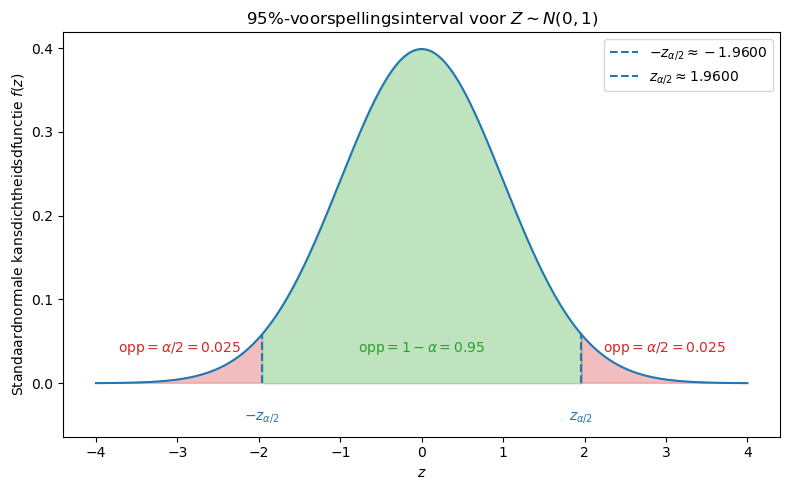

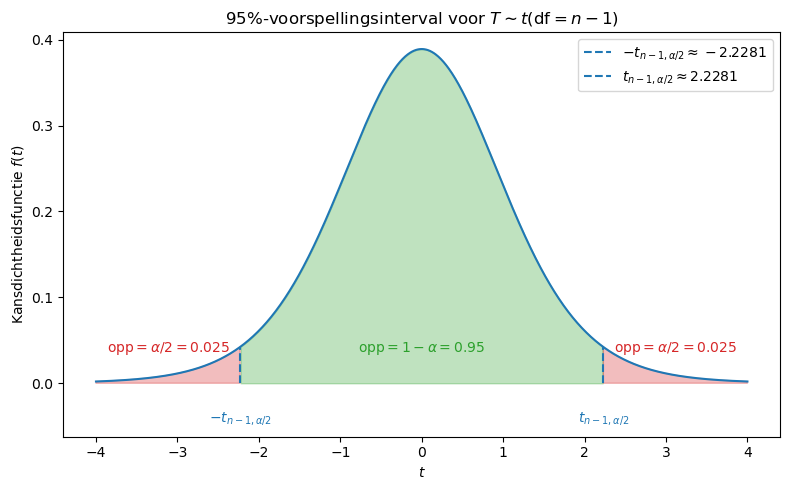

In [89]:
print(PMTPS_FIGURE_PATH)
prediction_interval_normal(mu=0, sigma=1, alpha=0.05, filename=PMTPS_FIGURE_PATH + "3_prediction_interval_z.png")
prediction_interval_t(df=10, alpha=0.05, filename=PMTPS_FIGURE_PATH + "3_prediction_interval_t.png")

## LaTeX code generation

In [16]:
def latex_sample_mean(data):
    n = len(data)
    mean = pretty_print(sample_mean(data))
    latex_code = f"""
        We berekenen het steekproefgemiddelde $\\overline{{x}}$ als volgt:
        \\begin{{align*}}
            \\overline{{x}} = \\frac{{x_1+x_2+\\ldots+x_n}}{{n}} = \\frac{{ {data[0]} + {data[1]} + \\ldots + {data[-1]} }}{{ {n} }} \\approx {mean}.
        \\end{{align*}}
    """
    return latex_code

def latex_sample_variance(data, ddof=1):
    n = len(data)
    mean = pretty_print(sample_mean(data))
    var = pretty_print(sample_variance(data, ddof))
    latex_code = f"""
        We berekenen de steekproefvariantie $s^2$ als volgt:
        \\begin{{align*}}
            s^2 &= \\frac{{ (x_1 - \\overline{{x}})^2 + (x_2 - \\overline{{x}})^2 + \\ldots + (x_n - \\overline{{x}})^2 }}{{ n - {ddof} }} \\\\
                &= \\frac{{ ({data[0]} - {mean})^2 + ({data[1]} - {mean})^2 + \\ldots + ({data[-1]} - {mean})^2 }}{{ {n} - {ddof} }} \\\\
                &\\approx {var}.
        \\end{{align*}}
    """
    return latex_code

def latex_sample_std(data, ddof=1):
    n = len(data)
    var = pretty_print(sample_variance(data, ddof))
    std = pretty_print(sample_std(data, ddof))
    latex_code = f"""
        We berekenen de steekproefstandaardafwijking $s$ door te wortel van de steekproefvariantie $s^2$ te nemen:
        \\begin{{align*}}
            s = \\sqrt{{ s^2 }} = \\sqrt{{ {var} }} \\approx {std}.
        \\end{{align*}}
    """
    return latex_code

### Voorbeeld gebruik

In [18]:
data1 = [113, 122, 119, 111, 120, 117, 123, 119, 114, 126, 110, 108]  # Steekproef van vertragingstijden
for data in [data1]:
    mean_code = latex_sample_mean(data)
    print(mean_code)
    
    var_code = latex_sample_variance(data)
    print(var_code)
    
    std_code = latex_sample_std(data)
    print(std_code)


        We berekenen het steekproefgemiddelde $\overline{x}$ als volgt:
        \begin{align*}
            \overline{x} = \frac{x_1+x_2+\ldots+x_n}{n} = \frac{ 113 + 122 + \ldots + 108 }{ 12 } \approx 116.8333.
        \end{align*}
    

        We berekenen de steekproefvariantie $s^2$ als volgt:
        \begin{align*}
            s^2 &= \frac{ (x_1 - \overline{x})^2 + (x_2 - \overline{x})^2 + \ldots + (x_n - \overline{x})^2 }{ n - 1 } \\
                &= \frac{ (113 - 116.8333)^2 + (122 - 116.8333)^2 + \ldots + (108 - 116.8333)^2 }{ 12 - 1 } \\
                &\approx 31.7879.
        \end{align*}
    

        We berekenen de steekproefstandaardafwijking $s$ door te wortel van de steekproefvariantie $s^2$ te nemen:
        \begin{align*}
            s = \sqrt{ s^2 } = \sqrt{ 31.7879 } \approx 5.6381.
        \end{align*}
    


In [19]:
# data1 = [10, 16, 18, 16, 13, 21, 18, 20, 12, 15, 12, 9, 14, 10, 15, 12, 19, 12, 13, 10]  # jaren onderwijs
# print(sorted(data1))

# data1 = [12.1, 11.9, 12.3, 11.8, 12.2, 12.0, 11.9, 12.4, 11.7, 12.1, 12.0, 11.8]  # Levertijd leverancier A
# data2 = [11.9, 7.3, 14.7, 6.0, 13.6, 8.0, 9.3, 5.0, 7.6, 11.4] # Levertijd leverancier B

# data1 = [22.2, 37.9, 24.4, 33.4, 27.5, 23.2, 39.2, 28.9, 26.1, 34.4, 39.3, 33.4, 30.8, 30.4, 33.2, 26.9, 36.2, 42.9, 32.9, 38.9]

# print(sorted(data1))

data1 = [18.2, 17.5, 18.8, 17.9, 18.4, 17.7, 18.1, 18.6]
data2 = [16.5, 19.4, 15.2, 18.8, 14.9, 17.6, 19.9, 16.1, 18.3, 15.8]

for data in [data1, data2]:
    mean_code = latex_sample_mean(data)
    print(mean_code)
    
    var_code = latex_sample_variance(data)
    print(var_code)
    
    std_code = latex_sample_std(data)
    print(std_code)


        We berekenen het steekproefgemiddelde $\overline{x}$ als volgt:
        \begin{align*}
            \overline{x} = \frac{x_1+x_2+\ldots+x_n}{n} = \frac{ 18.2 + 17.5 + \ldots + 18.6 }{ 8 } \approx 18.1500.
        \end{align*}
    

        We berekenen de steekproefvariantie $s^2$ als volgt:
        \begin{align*}
            s^2 &= \frac{ (x_1 - \overline{x})^2 + (x_2 - \overline{x})^2 + \ldots + (x_n - \overline{x})^2 }{ n - 1 } \\
                &= \frac{ (18.2 - 18.1500)^2 + (17.5 - 18.1500)^2 + \ldots + (18.6 - 18.1500)^2 }{ 8 - 1 } \\
                &\approx 0.1971.
        \end{align*}
    

        We berekenen de steekproefstandaardafwijking $s$ door te wortel van de steekproefvariantie $s^2$ te nemen:
        \begin{align*}
            s = \sqrt{ s^2 } = \sqrt{ 0.1971 } \approx 0.4440.
        \end{align*}
    

        We berekenen het steekproefgemiddelde $\overline{x}$ als volgt:
        \begin{align*}
            \overline{x} = \frac{x_1+x_2+\ldots+x_n}{n} = \fr